In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [24]:
df = pd.read_csv("../data/raw/Dataset.csv")
print("Shape:", df.shape)
df.info()

Shape: (8790, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [25]:
df.head(10)

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
5,s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
6,s10,Movie,The Starling,Theodore Melfi,United States,9/24/2021,2021,PG-13,104 min,"Comedies, Dramas"
7,s939,Movie,Motu Patlu in the Game of Zones,Suhas Kadav,India,5/1/2021,2019,TV-Y7,87 min,"Children & Family Movies, Comedies, Music & Mu..."
8,s13,Movie,Je Suis Karl,Christian Schwochow,Germany,9/23/2021,2021,TV-MA,127 min,"Dramas, International Movies"
9,s940,Movie,Motu Patlu in Wonderland,Suhas Kadav,India,5/1/2021,2013,TV-Y7,76 min,"Children & Family Movies, Music & Musicals"


In [26]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate show_id:", df["show_id"].duplicated().sum())
print("Duplicate (title, type, release_year):", df.duplicated(subset=["title", "type", "release_year"]).sum())

for col in ["director", "country", "rating", "type"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().head(8))

Duplicate rows: 0
Duplicate show_id: 0
Duplicate (title, type, release_year): 3

--- director ---
director
Not Given                 2588
Rajiv Chilaka               20
Alastair Fothergill         18
Raúl Campos, Jan Suter      18
Marcus Raboy                16
Suhas Kadav                 16
Jay Karas                   14
Cathy Garcia-Molina         13
Name: count, dtype: int64

--- country ---
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
Name: count, dtype: int64

--- rating ---
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
Name: count, dtype: int64

--- type ---
type
Movie      6126
TV Show    2664
Name: count, dtype: int64


In [27]:
suspicious = ["", " ", "unknown", "not given", "n/a", "na", "none", "null", "nan", "-"]

for col in df.columns:
    s = df[col].astype(str).str.strip().str.lower()
    count = s.isin(suspicious).sum()
    if count > 0:
        print(f"{col}: {count} suspicious values")

title: 1 suspicious values
director: 2588 suspicious values
country: 287 suspicious values


In [28]:
print("Unique types:", df["type"].unique())
print("\nUnique ratings:", df["rating"].unique())
print("\nDuration samples:", df["duration"].sample(8, random_state=1).tolist())
print("\ndate_added samples:", df["date_added"].sample(8, random_state=1).tolist())
print("\nrelease_year range:", df["release_year"].min(), "to", df["release_year"].max())

Unique types: ['Movie' 'TV Show']

Unique ratings: ['PG-13' 'TV-MA' 'TV-PG' 'TV-14' 'TV-Y7' 'TV-Y' 'PG' 'TV-G' 'R' 'G'
 'NC-17' 'NR' 'TV-Y7-FV' 'UR']

Duration samples: ['1 Season', '121 min', '1 Season', '1 Season', '5 Seasons', '84 min', '16 min', '25 min']

date_added samples: ['5/21/2020', '12/1/2017', '12/9/2020', '6/30/2021', '9/5/2021', '4/13/2021', '3/8/2020', '10/4/2016']

release_year range: 1925 to 2021


In [29]:
suspicious = ["", "unknown", "not given", "n/a", "na", "none", "null", "nan", "-"]

for col in ["title", "director", "country"]:
    s = df[col].astype(str).str.strip().str.lower()
    print(f"\n--- {col} ---")
    print(df.loc[s.isin(suspicious), col].value_counts().head())

print("\nRows with suspicious title:")
s = df["title"].astype(str).str.strip().str.lower()
display(df[s.isin(suspicious)])



--- title ---
title
Unknown    1
Name: count, dtype: int64

--- director ---
director
Not Given    2588
Name: count, dtype: int64

--- country ---
country
Not Given    287
Name: count, dtype: int64

Rows with suspicious title:


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
1336,s1468,Movie,Unknown,Jaume Collet-Serra,United Kingdom,1/1/2021,2011,PG-13,113 min,"Action & Adventure, Thrillers"


In [30]:
df_clean = df.copy()

# 1) شيل المسافات الزايدة من كل الأعمدة النصية
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# 2) حوّل القيم الناقصة المخبية إلى NaN
for col in ["director", "country"]:
    mask = df_clean[col].str.lower().isin(suspicious)
    df_clean.loc[mask, col] = np.nan

# 3) املأ الناقص بـ Unknown
df_clean["director"] = df_clean["director"].fillna("Unknown")
df_clean["country"] = df_clean["country"].fillna("Unknown")

print(df_clean[["director", "country"]].eq("Unknown").sum())

director    2588
country      287
dtype: int64


In [31]:
# Type
df_clean["type"] = df_clean["type"].str.lower().map({"movie": "Movie", "tv show": "TV Show"})

# Rating: وحّد القيم الغريبة
df_clean["rating"] = df_clean["rating"].str.upper().replace({
    "NR": "Not Rated",
    "UR": "Not Rated",
    "TV-Y7-FV": "TV-Y7"
})

# Country: شيل الفواصل الزايدة والمسافات (بعض الصفوف فيها دولتين أو أكتر)
def clean_country(x):
    parts = [p.strip() for p in x.split(",") if p.strip()]
    return ", ".join(parts) if parts else "Unknown"

df_clean["country"] = df_clean["country"].apply(clean_country)

print(df_clean["rating"].value_counts())
print(df_clean["country"].value_counts().head(8))

rating
TV-MA        3205
TV-14        2157
TV-PG         861
R             799
PG-13         490
TV-Y7         339
TV-Y          306
PG            287
TV-G          220
Not Rated      82
G              41
NC-17           3
Name: count, dtype: int64
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Unknown            287
Canada             271
Japan              259
South Korea        214
Name: count, dtype: int64


In [32]:
# date_added -> datetime
df_clean["date_added"] = pd.to_datetime(df_clean["date_added"], format="%m/%d/%Y", errors="coerce")
df_clean["year_added"] = df_clean["date_added"].dt.year
df_clean["month_added"] = df_clean["date_added"].dt.month

# duration -> رقم + وحدة
df_clean["duration_value"] = df_clean["duration"].str.extract(r"(\d+)").astype(int)
df_clean["duration_unit"] = df_clean["duration"].str.extract(r"(min|Season)")

# Duplicates
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=["title", "type", "release_year"])
print("Removed duplicates:", before - len(df_clean))

Removed duplicates: 4


In [33]:
print("Shape:", df_clean.shape)
print("\nNulls:\n", df_clean.isna().sum())
display(df_clean.head())

df_clean.to_csv("../data/cleaned/netflix_cleaned.csv", index=False)
print("\nSaved successfully")

Shape: (8786, 14)

Nulls:
 show_id           0
type              0
title             0
director          0
country           0
date_added        0
release_year      0
rating            0
duration          0
listed_in         0
year_added        0
month_added       0
duration_value    0
duration_unit     0
dtype: int64


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,90,min
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,1,Season
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,125,min



Saved successfully


In [34]:
print("Shape:", df_clean.shape)
print(df_clean["type"].value_counts())
print("Nulls:", df_clean.isna().sum().sum())

Shape: (8786, 14)
type
Movie      6123
TV Show    2663
Name: count, dtype: int64
Nulls: 0


In [35]:
raw = pd.read_csv("../data/raw/Dataset.csv")
dups = raw[raw.duplicated(subset=["title", "type", "release_year"], keep=False)].sort_values("title")
display(dups[["show_id", "title", "type", "release_year", "country", "date_added"]])


,show_id,title,type,release_year,country,date_added
2925,s3963,15-Aug,Movie,2019,India,3/29/2019
4261,s5967,15-Aug,Movie,2019,India,3/29/2019
3285,s4523,22-Jul,Movie,2018,Norway,10/10/2018
4260,s5966,22-Jul,Movie,2018,Norway,10/10/2018
393,s3997,9-Feb,TV Show,2018,Pakistan,3/20/2019
537,s5965,9-Feb,TV Show,2018,Pakistan,3/20/2019


## Task 1 Summary: Data Quality Decisions

- **Hidden missing values:** `isna()` reported zero nulls, but missing data was stored as the text "Not Given" in `director` (2,588 rows, about 29%) and `country` (287 rows, about 3%). These were converted to NaN and then filled with "Unknown" instead of dropping rows, to avoid losing roughly a third of the dataset.
- **Duplicates:** 4 records were removed based on `title + type + release_year`. No duplicate `show_id` values existed.
- **Standardization:** `type` was normalized to "Movie" / "TV Show". Ratings "NR" and "UR" were merged into "Not Rated", and "TV-Y7-FV" was merged into "TV-Y7". Country strings were stripped of extra spaces and separators.
- **Feature engineering:** `date_added` was converted to datetime with `year_added` and `month_added` extracted. `duration` was split into a numeric value and a unit (min / Season).
- **Result:** a clean dataset of 8,786 rows and 14 columns, exported to `data/cleaned/netflix_cleaned.csv`.

TASK 2


In [36]:
df = pd.read_csv("../data/cleaned/netflix_cleaned.csv", parse_dates=["date_added"])
colors = ["#E50914", "#564d4d"]
print(df.shape)

(8786, 14)


In [37]:
counts = df["type"].value_counts()
percent = df["type"].value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({"Count": counts, "Percentage %": percent}))

,Count,Percentage %
type,,
Movie,6123,69.7
TV Show,2663,30.3


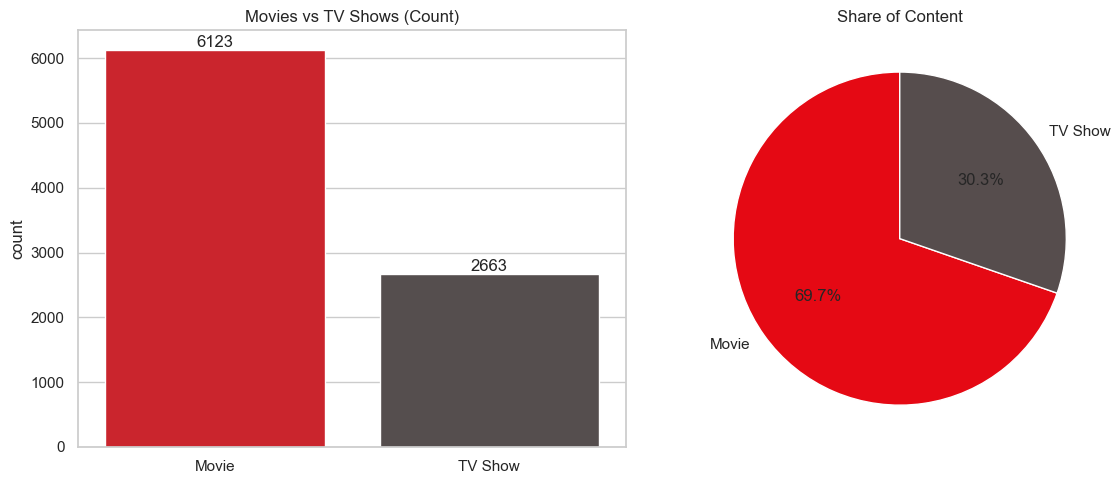

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(data=df, x="type", order=counts.index, hue="type",
              palette=colors, legend=False, ax=axes[0])
axes[0].set_title("Movies vs TV Shows (Count)")
axes[0].set_xlabel("")
for bar in axes[0].patches:
    axes[0].annotate(int(bar.get_height()),
                     (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     ha="center", va="bottom")
axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=colors, startangle=90)
axes[1].set_title("Share of Content")
plt.tight_layout()
plt.savefig("../charts/task2_content_type.png", dpi=150)
plt.show()

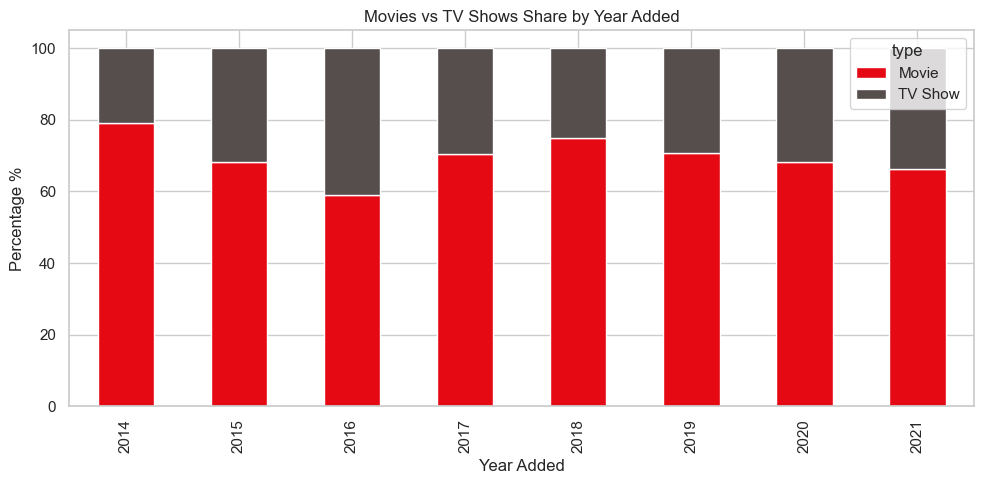

Avg movie length (min): 99.6
Avg TV show seasons: 1.75


In [39]:
yearly = (df[df["year_added"] >= 2014].groupby(["year_added", "type"]).size().unstack(fill_value=0))
(yearly.div(yearly.sum(axis=1), axis=0) * 100).plot(kind="bar", stacked=True, figsize=(10, 5), color=colors)
plt.title("Movies vs TV Shows Share by Year Added")
plt.ylabel("Percentage %"); plt.xlabel("Year Added")
plt.tight_layout()
plt.savefig("../charts/task2_share_by_year.png", dpi=150)
plt.show()

print("Avg movie length (min):", round(df[df["duration_unit"] == "min"]["duration_value"].mean(), 1))
print("Avg TV show seasons:", round(df[df["duration_unit"] == "Season"]["duration_value"].mean(), 2))

## Task 2 Key Findings

- Netflix's catalog is movie-heavy: **6,123 Movies (69.7%)** versus **2,663 TV Shows (30.3%)**, roughly a 7:3 split.
- The average movie runs about **100 minutes**, while the average TV show has only **1.75 seasons**, which suggests most series are short-run or limited series.
- The 100% stacked chart by year added shows how the Movie/TV mix has shifted over time, which helps identify whether Netflix is moving toward more series.

TASK 3

In [40]:
# الصف الواحد فيه أكتر من دولة أحياناً، فنفصلهم
c = df.assign(country=df["country"].str.split(",")).explode("country").reset_index(drop=True)
c["country"] = c["country"].str.strip()
c = c[c["country"] != "Unknown"]

country_counts = c["country"].value_counts()
top10 = country_counts.head(10)

ranking = pd.DataFrame({
    "Titles": top10,
    "Share % of catalog": (top10 / len(df) * 100).round(1)
})
ranking.index.name = "Country"
display(ranking)

,Titles,Share % of catalog
Country,,
United States,3240,36.9
India,1056,12.0
United Kingdom,638,7.3
Pakistan,420,4.8
Canada,271,3.1
Japan,259,2.9
South Korea,214,2.4
France,213,2.4
Spain,182,2.1


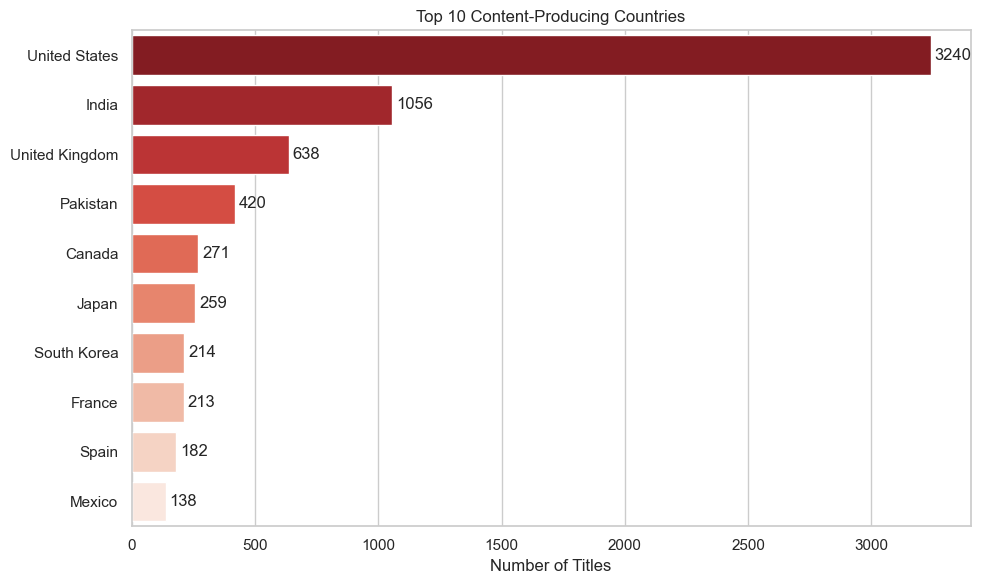

In [41]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top10.values, y=top10.index, hue=top10.index, palette="Reds_r", legend=False, ax=ax)
ax.set_title("Top 10 Content-Producing Countries")
ax.set_xlabel("Number of Titles"); ax.set_ylabel("")
for i, v in enumerate(top10.values):
    ax.text(v + 15, i, str(v), va="center")
plt.tight_layout()
plt.savefig("../charts/task3_top10_countries.png", dpi=150)
plt.show()

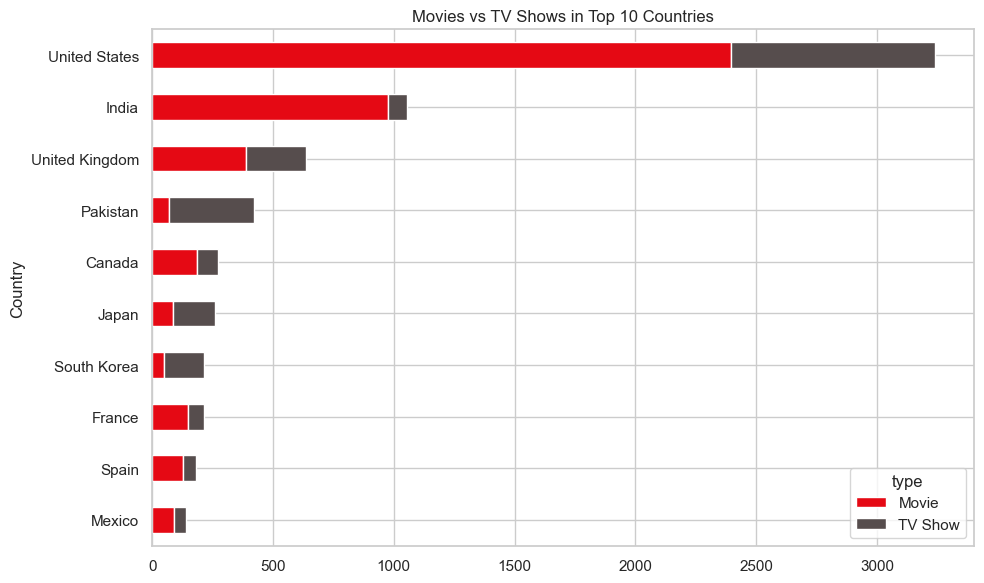

type,Movie,TV Show,TV Show %
Country,,,
Pakistan,71,349,83.1
South Korea,49,165,77.1
Japan,87,172,66.4
United Kingdom,387,251,39.3
Mexico,90,48,34.8
Canada,187,84,31.0
France,148,65,30.5
Spain,129,53,29.1
United States,2395,845,26.1


In [42]:
type_by_country = (c[c["country"].isin(top10.index)]
                   .groupby(["country", "type"]).size().unstack(fill_value=0)
                   .loc[top10.index])

type_by_country.plot(kind="barh", stacked=True, figsize=(10, 6), color=colors)
plt.title("Movies vs TV Shows in Top 10 Countries")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../charts/task3_type_by_country.png", dpi=150)
plt.show()

type_by_country["TV Show %"] = (type_by_country["TV Show"] /
                                (type_by_country["Movie"] + type_by_country["TV Show"]) * 100).round(1)
display(type_by_country.sort_values("TV Show %", ascending=False))

In [43]:
map_df = country_counts.reset_index()
map_df.columns = ["country", "titles"]
fig = px.choropleth(map_df, locations="country", locationmode="country names",
                    color="titles", color_continuous_scale="Reds",
                    title="Netflix Titles by Country")
fig.show()

## Task 3 Key Findings

- **The United States dominates** with 3,240 titles (36.9% of the catalog), followed by **India** (1,056, 12.0%) and the **United Kingdom** (638, 7.3%). These three countries alone account for over half of all titles, so the catalog is concentrated in a few markets.
- **Content mix differs sharply by country.** India is almost entirely movie-driven (only 7.7% TV Shows), while Pakistan (83.1%), South Korea (77.1%) and Japan (66.4%) lean heavily toward TV Shows. The US sits near the overall average at 26.1% TV Shows.
- Outside the top three, a long tail of countries (Canada, Japan, South Korea, France, Spain, Mexico) each contribute between 1.6% and 3.1% of titles.
- *Note:* co-productions are counted once for each listed country, so country shares are relative to the total number of titles and may overlap.

tASK 4

Peak release year: 2018 with 1144 titles


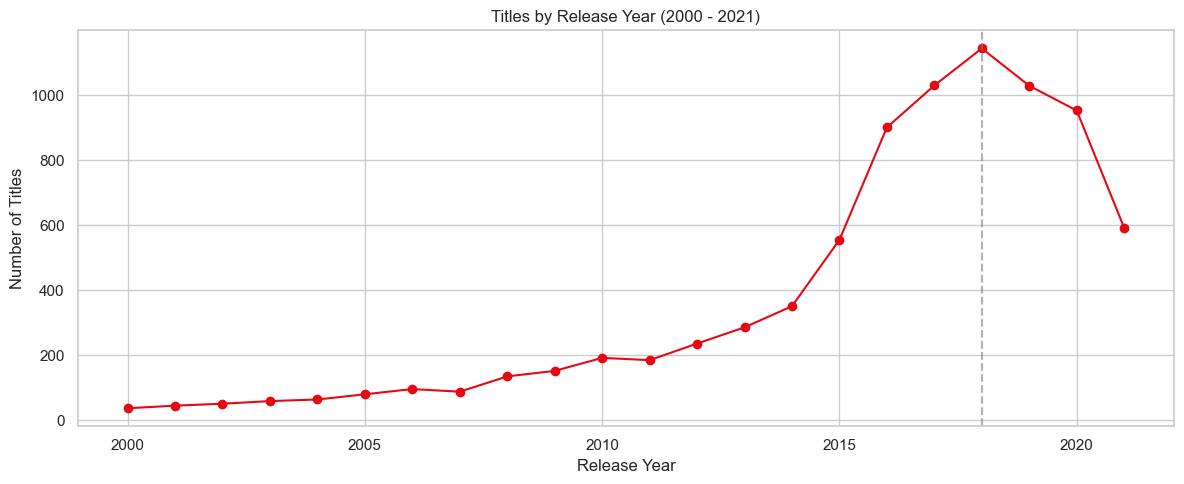

In [44]:
yearly_releases = df.groupby("release_year").size()
recent = yearly_releases[yearly_releases.index >= 2000]

peak_year = yearly_releases.idxmax()
print("Peak release year:", peak_year, "with", yearly_releases.max(), "titles")

plt.figure(figsize=(12, 5))
plt.plot(recent.index, recent.values, marker="o", color="#E50914")
plt.axvline(peak_year, linestyle="--", color="grey", alpha=0.6)
plt.title("Titles by Release Year (2000 - 2021)")
plt.xlabel("Release Year"); plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig("../charts/task4_release_trend.png", dpi=150)
plt.show()

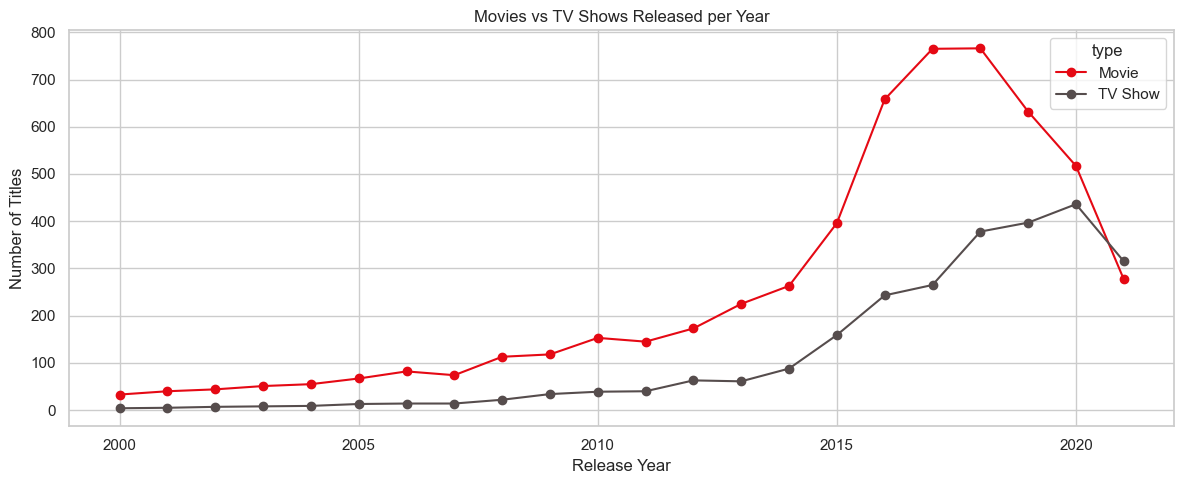

In [45]:
by_type = df[df["release_year"] >= 2000].groupby(["release_year", "type"]).size().unstack(fill_value=0)
by_type.plot(figsize=(12, 5), marker="o", color=colors)
plt.title("Movies vs TV Shows Released per Year")
plt.xlabel("Release Year"); plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig("../charts/task4_release_by_type.png", dpi=150)
plt.show()

,Titles Added,Growth %
year_added,,
2014,24,118.2
2015,82,241.7
2016,426,419.5
2017,1185,178.2
2018,1647,39.0
2019,2013,22.2
2020,1879,-6.7
2021,1498,-20.3


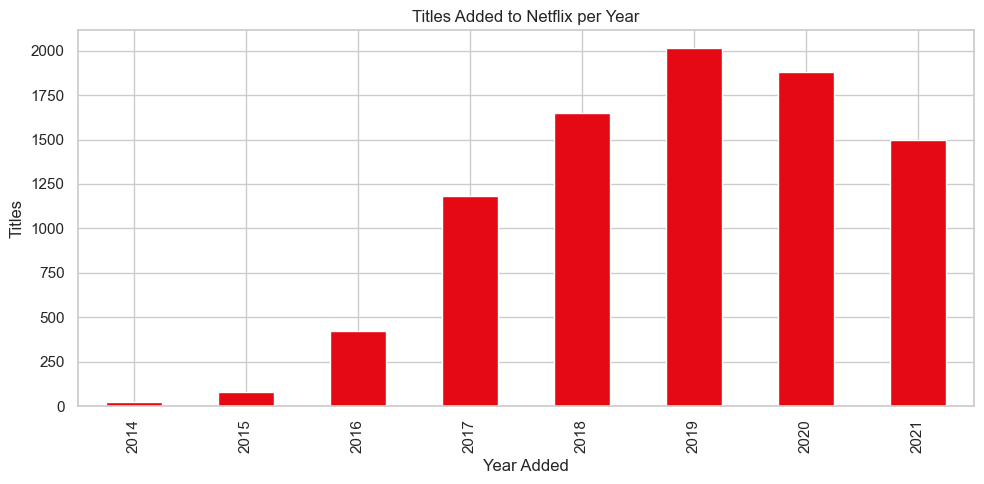

In [46]:
# إمتى Netflix ضافت المحتوى (مش إمتى اتنتج)
added_per_year = df.groupby("year_added").size()
growth = added_per_year.pct_change().mul(100).round(1)

growth_table = pd.DataFrame({"Titles Added": added_per_year, "Growth %": growth})
display(growth_table.tail(8))

added_per_year.loc[2014:].plot(kind="bar", figsize=(10, 5), color="#E50914")
plt.title("Titles Added to Netflix per Year")
plt.xlabel("Year Added"); plt.ylabel("Titles")
plt.tight_layout()
plt.savefig("../charts/task4_added_per_year.png", dpi=150)
plt.show()

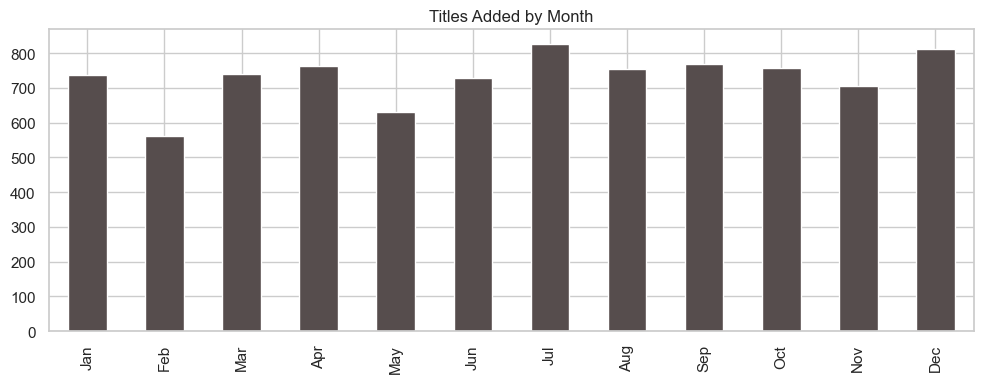

Median gap between release and Netflix addition (years): 1.0


In [47]:
# أكتر شهر بتضاف فيه محتوى + الفجوة بين الإنتاج والإضافة
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
monthly = df.groupby("month_added").size()
monthly.index = [month_names[int(m) - 1] for m in monthly.index]
monthly.plot(kind="bar", figsize=(10, 4), color="#564d4d")
plt.title("Titles Added by Month")
plt.tight_layout()
plt.savefig("../charts/task4_monthly.png", dpi=150)
plt.show()

df["years_to_netflix"] = df["year_added"] - df["release_year"]
print("Median gap between release and Netflix addition (years):", df["years_to_netflix"].median())

## Task 4 Key Findings

- **Release volume peaked in 2018** with 1,144 titles, then declined, consistent with fewer new releases entering the catalog in 2019 to 2021.
- **Netflix's catalog additions grew rapidly then slowed:** titles added per year rose from 1,185 (2017) to 1,647 (2018) and peaked at **2,013 in 2019** (+22.2% vs 2018). Additions then fell 6.7% in 2020, a drop that coincides with the COVID-19 period, although this dataset cannot prove the cause.
- **2021 is an incomplete year.** The data ends in late 2021, so the 20.3% drop shown for 2021 is not a reliable decline and should not be interpreted as a real trend.
- Most titles are added to the platform soon after release (**median gap of 1 year**), which shows the catalog is dominated by recent content rather than older library titles.
- Additions are not evenly spread through the year; the monthly chart shows July as the peak month for additions.

TASK 5

In [48]:
audience_map = {
    "TV-Y": "Kids", "TV-Y7": "Kids", "TV-G": "Kids", "G": "Kids",
    "TV-PG": "Teens", "PG": "Teens", "PG-13": "Teens", "TV-14": "Teens",
    "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults",
    "Not Rated": "Not Rated"
}
df["audience"] = df["rating"].map(audience_map)
print("Unmapped ratings:", df["audience"].isna().sum())   # لازم يطلع 0

rating_counts = df["rating"].value_counts()
fig = px.bar(rating_counts, x=rating_counts.index, y=rating_counts.values,
             labels={"x": "Rating", "y": "Titles"}, title="Content by Rating",
             color_discrete_sequence=["#E50914"])
fig.show()

Unmapped ratings: 0


In [49]:
# الـ Genres (برضو فيها أكتر من قيمة في الخلية)
g = df.assign(genre=df["listed_in"].str.split(",")).explode("genre").reset_index(drop=True)
g["genre"] = g["genre"].str.strip()
g["audience"] = g["rating"].map(audience_map)

top_genres = g["genre"].value_counts().head(10).sort_values()
fig = px.bar(top_genres, x=top_genres.values, y=top_genres.index, orientation="h",
             labels={"x": "Titles", "y": "Genre"}, title="Top 10 Genres",
             color_discrete_sequence=["#E50914"])
fig.show()

In [50]:
# مقارنة التقييمات بين Movies و TV Shows
fig = px.histogram(df, x="rating", color="type", barmode="group",
                   color_discrete_sequence=colors, title="Ratings: Movies vs TV Shows",
                   category_orders={"rating": rating_counts.index.tolist()})
fig.show()

ct = pd.crosstab(df["rating"], df["type"])
display(ct)

type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
Not Rated,78,4
PG,287,0
PG-13,490,0
R,796,2
TV-14,1426,729
TV-G,126,94
TV-MA,2061,1143


In [51]:
fig = px.sunburst(df, path=["type", "audience", "rating"], title="Type > Audience > Rating",
                  color_discrete_sequence=px.colors.sequential.Reds_r)
fig.show()

fig = px.treemap(df, path=["type", "audience", "rating"], title="Audience Segmentation Treemap",
                 color_discrete_sequence=px.colors.sequential.Reds_r)
fig.show()

In [52]:
# أنهي Genres بتستهدف أنهي جمهور
top8 = g["genre"].value_counts().head(8).index
sub = g[g["genre"].isin(top8)]
genre_audience = pd.crosstab(sub["genre"], sub["audience"])

fig = px.imshow(genre_audience, text_auto=True, color_continuous_scale="Reds",
                title="Genre vs Target Audience", aspect="auto")
fig.show()

## Task 5 Key Findings

- **The catalog targets mature audiences.** TV-MA is the most common rating with about 3,200 titles (36.5%), followed by TV-14 (about 2,150). By audience group: **Adults 45.6%, Teens 43.2%, Kids only 10.3%**.
- **TV Shows skew more toward children than Movies:** about 17.4% of TV Shows carry a kids rating (TV-Y, TV-Y7, TV-G) versus 7.2% of Movies.
- **Top genres are International Movies (2,751), Dramas (2,423) and Comedies (1,673),** followed by International TV Shows (1,348) and Documentaries (869). International content is a core pillar of the catalog.
- **Genres target different audiences:** Independent Movies are strongly adult-oriented (539 adult vs 194 teen titles), Comedies lean toward teens (933 vs 613), and Dramas are split almost evenly between adults and teens.
- Traditional film ratings (G, PG, PG-13, R, NC-17) appear only on Movies, while TV Shows use the TV-xx rating scale.

TASK 6

In [53]:
display(df.describe(include="all").T)
print("\nMissing 'Unknown' values:")
print("Director:", (df["director"] == "Unknown").sum(), "| Country:", (df["country"] == "Unknown").sum())

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
show_id,8786,8786,s8786,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8786,2,Movie,6123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8786,8786,YOM,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,8786,4528,Unknown,2587,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,8786,86,United States,3240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8786,NaN,NaN,NaN,2019-05-17 22:11:39.840655616,2008-01-01 00:00:00,2018-04-06 00:00:00,2019-07-03 12:00:00,2020-08-20 00:00:00,2021-09-25 00:00:00,NaN
release_year,8786.0,NaN,NaN,NaN,2014.181766,1925.0,2013.0,2017.0,2019.0,2021.0,8.827137
rating,8786,12,TV-MA,3204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8786,220,1 Season,1790,NaN,NaN,NaN,NaN,NaN,NaN,NaN
listed_in,8786,513,"Dramas, International Movies",362,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing 'Unknown' values:
Director: 2587 | Country: 287


In [54]:
directors = (df[df["director"] != "Unknown"]["director"]
             .str.split(",").explode().str.strip().value_counts().head(10))
display(directors)

director
Rajiv Chilaka          23
Jan Suter              21
Alastair Fothergill    19
Raúl Campos            19
Suhas Kadav            16
Marcus Raboy           16
Jay Karas              15
Cathy Garcia-Molina    13
Jay Chapman            12
Youssef Chahine        12
Name: count, dtype: int64

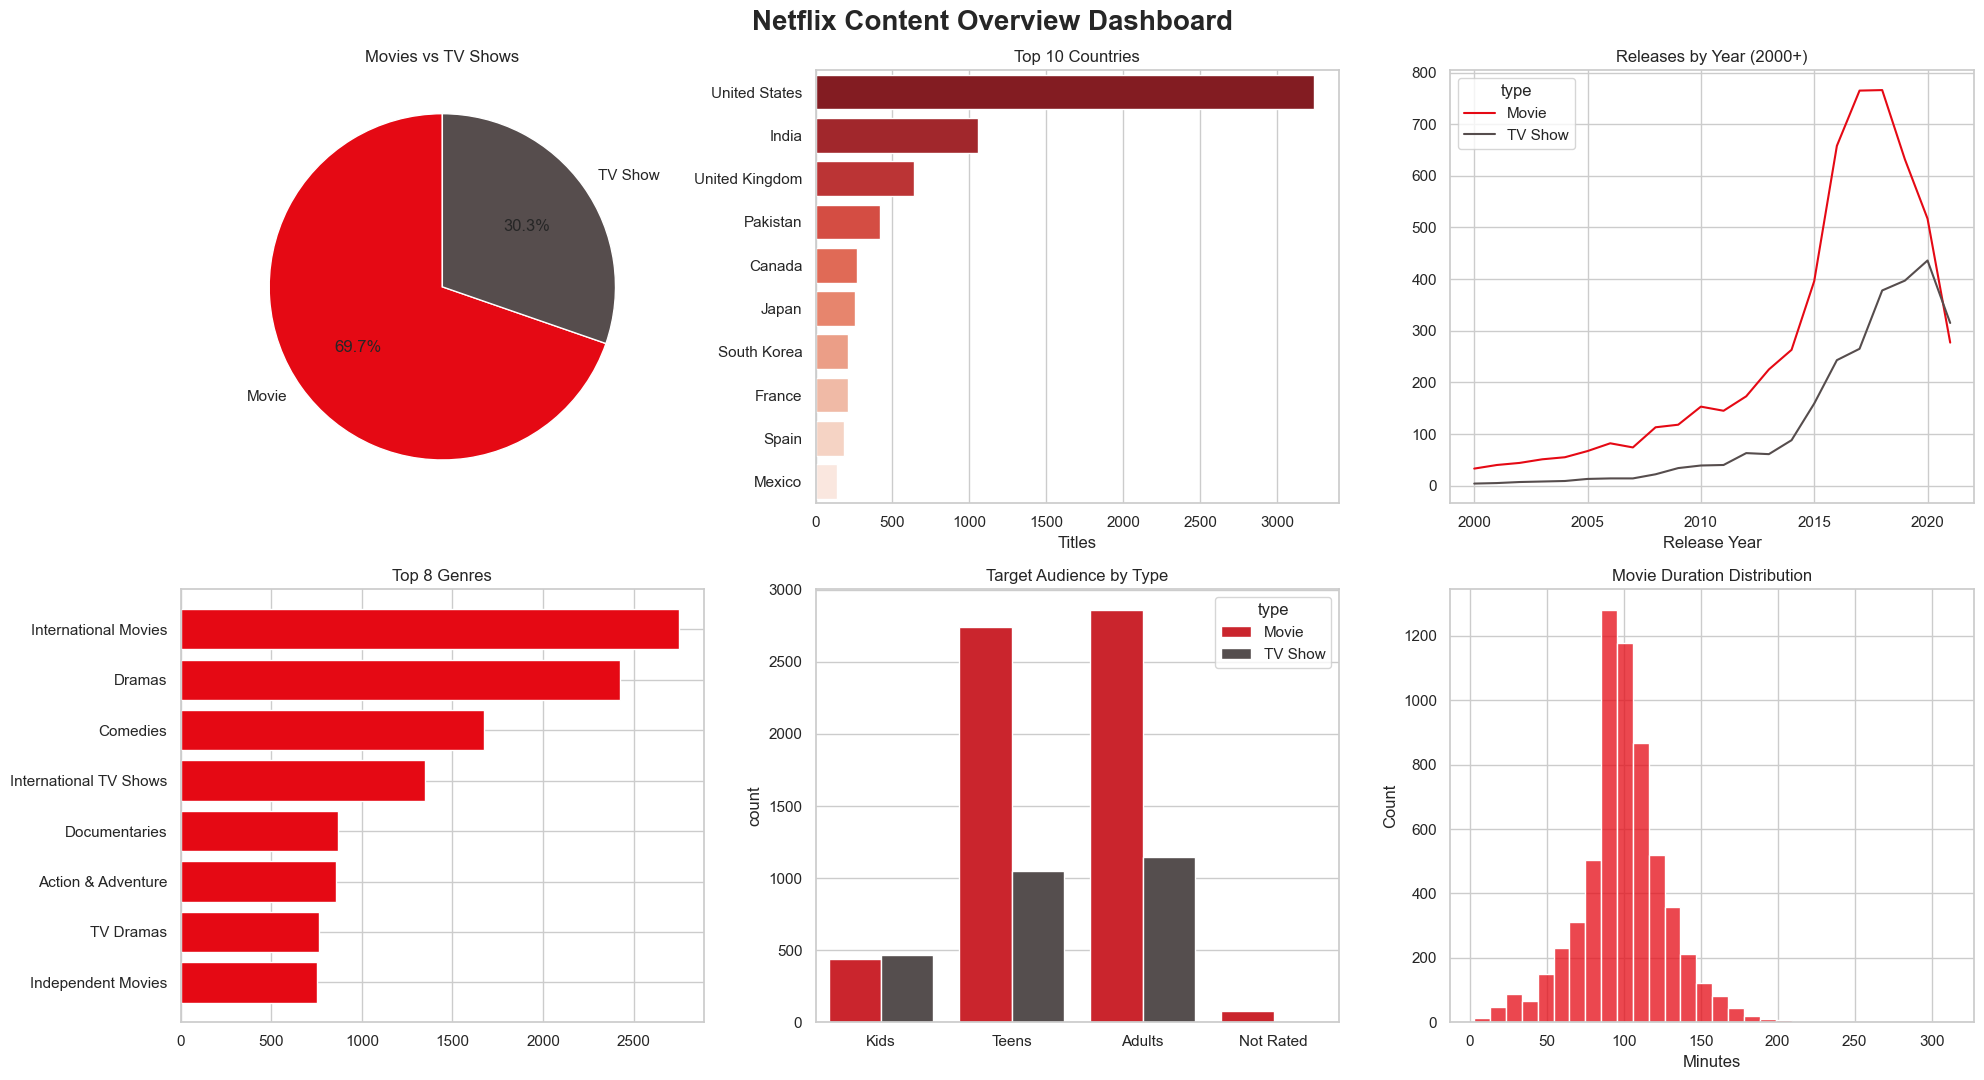

In [55]:
yt = df[df["release_year"] >= 2000].groupby(["release_year", "type"]).size().unstack(fill_value=0)
t8 = g["genre"].value_counts().head(8).sort_values()

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle("Netflix Content Overview Dashboard", fontsize=20, fontweight="bold")

axes[0, 0].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=colors, startangle=90)
axes[0, 0].set_title("Movies vs TV Shows")

sns.barplot(x=top10.values, y=top10.index, hue=top10.index, palette="Reds_r", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Top 10 Countries"); axes[0, 1].set_xlabel("Titles"); axes[0, 1].set_ylabel("")

yt.plot(ax=axes[0, 2], color=colors)
axes[0, 2].set_title("Releases by Year (2000+)"); axes[0, 2].set_xlabel("Release Year")

axes[1, 0].barh(t8.index, t8.values, color="#E50914")
axes[1, 0].set_title("Top 8 Genres")

sns.countplot(data=df, x="audience", order=["Kids", "Teens", "Adults", "Not Rated"],
              hue="type", palette=colors, ax=axes[1, 1])
axes[1, 1].set_title("Target Audience by Type"); axes[1, 1].set_xlabel("")

sns.histplot(df[df["duration_unit"] == "min"]["duration_value"], bins=30, color="#E50914", ax=axes[1, 2])
axes[1, 2].set_title("Movie Duration Distribution"); axes[1, 2].set_xlabel("Minutes")

plt.tight_layout()
plt.savefig("../charts/task6_dashboard1.png", dpi=150)
plt.show()

In [56]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

added = df.groupby(["year_added", "type"]).size().reset_index(name="count")
dd = directors.sort_values()
seasons = df[df["duration_unit"] == "Season"]["duration_value"].value_counts().sort_index()
months = df.groupby("month_added").size()

fig = make_subplots(rows=2, cols=2, subplot_titles=(
    "Titles Added per Year", "Top 10 Directors", "TV Show Seasons", "Titles Added by Month"))

for t, col in zip(["Movie", "TV Show"], colors):
    s = added[added["type"] == t]
    fig.add_trace(go.Scatter(x=s["year_added"], y=s["count"], mode="lines+markers",
                             name=t, line=dict(color=col)), row=1, col=1)

fig.add_trace(go.Bar(x=dd.values, y=dd.index, orientation="h", marker_color="#E50914", showlegend=False), row=1, col=2)
fig.add_trace(go.Bar(x=seasons.index, y=seasons.values, marker_color="#564d4d", showlegend=False), row=2, col=1)
fig.add_trace(go.Bar(x=months.index, y=months.values, marker_color="#E50914", showlegend=False), row=2, col=2)

fig.update_layout(height=800, title_text="Netflix Growth & Production Dashboard", template="plotly_white")
fig.show()

## Task 6: Business Insights Report

### Executive Summary
Analysis of 8,786 Netflix titles shows a catalog that is movie-heavy (70%), concentrated in a few countries (US, India and UK hold about 56% of titles when counted per country), aimed mainly at adults and teens (89%), and shaped by rapid growth until 2019 followed by slower additions in 2020 and 2021.

### Key Insights
1. **Content mix:** 69.7% Movies vs 30.3% TV Shows.
2. **Geography:** The US alone provides 36.9% of titles; India is the second-largest source but almost exclusively movies.
3. **Growth:** Additions peaked in 2019 (2,013 titles) and fell 6.7% in 2020.
4. **Audience:** Only 10.3% of titles are rated for kids, versus 45.6% for adults.
5. **Genre:** International Movies and Dramas lead; International content is a major part of the catalog.

### Recommendations
1. **Expand kids and family content.** Kids titles are only about 10% of the catalog, and TV Shows are where kids content is strongest (17.4% of series vs 7.2% of movies). Investing in animated and family series would diversify the audience base.
2. **Grow TV Show content in movie-heavy markets.** India is 92.3% movies. Since series drive repeat viewing, local-language series are a potential growth area there.
3. **Invest in regions where TV Shows already perform as the majority format** (South Korea, Japan). This is a data-supported signal that these markets favor series.
4. **Diversify beyond the top three countries.** About 56% of titles come from the US, India and the UK. Growing contributions from Canada, France, Spain and Mexico would reduce dependence on a few markets.
5. **Keep a steady release pipeline.** Additions slowed after 2019. A consistent flow of new titles helps maintain catalog freshness, especially since most titles are added within a year of release.
6. **Improve metadata quality.** About 29% of titles lack director information. Better metadata would improve search, recommendations and future analysis.

### Limitations
- The dataset describes catalog composition only; it has no viewership data, so a high title count does not necessarily mean high popularity.
- 2021 is an incomplete year and should not be used to judge trends.
- Director is unknown for about 29% of titles and country for about 3%.
- Co-productions are counted once per listed country in the country analysis.